# 05 · Modelos baseline y validación walk-forward

**Nivel de pronóstico:** producto × municipio (724 series activas). **Esquema:** se entrena con datos hasta el año de origen O y se pronostica O+1 … O+5 (sin pasar de 2023), con ventana que se expande:

| Origen | Entrena | Evalúa |
|---|---|---|
| 2018 | 2000-2018 | 2019-2023 (h = 1..5) |
| 2019 | 2000-2019 | 2020-2023 (h = 1..4) |
| 2020 | 2000-2020 | 2021-2023 |
| 2021 | 2000-2021 | 2022-2023 |
| 2022 | 2000-2022 | 2023 |

**Modelos:** ingenuo (último valor), deriva, ETS con tendencia amortiguada y promedio de 5 años (los simplificados solo usan ingenuo y promedio).
**Métricas:** MASE (escala = error medio del ingenuo dentro del entrenamiento) y WAPE, más la mejora relativa frente al ingenuo en las mismas filas.

In [1]:
import os, sys
from pathlib import Path
from importlib import import_module

ROOT = Path.cwd().resolve()
while not (ROOT / "config/ML_C/parametros.yaml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src/ML_C"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import CFG, RAW, CLEAN, RES
from graficos import estilo, COLORES
estilo(); pd.set_option("display.max_columns", 30, "display.width", 160)

In [2]:
REENTRENAR = False   # True vuelve a correr 05_baselines.py (requiere statsmodels; tarda unos minutos)
if REENTRENAR:
    b5 = import_module("05_baselines"); b5.main()
    pr = pd.read_csv(RES / "predicciones_baselines.csv", dtype={"cod_dane": str})
    b5.metricas(pr).round(4).to_csv(RES / "metricas_baselines.csv", index=False, encoding="utf-8-sig")
pr = pd.read_csv(RES / "predicciones_baselines.csv", dtype={"cod_dane": str})
met = pd.read_csv(RES / "metricas_baselines.csv")
print(f"{len(pr):,} predicciones | {pr[['producto','cod_dane']].drop_duplicates().shape[0]} series | orígenes {sorted(int(o) for o in pr.origen_anio.unique())}")

10,567 predicciones | 723 series | orígenes [2018, 2019, 2020, 2021, 2022]


In [3]:
met[met.producto == "TOTAL"].set_index("modelo")[["n_obs", "MASE", "WAPE", "mejora_MASE_vs_naive", "mejora_WAPE_vs_naive"]]

,n_obs,MASE,WAPE,mejora_MASE_vs_naive,mejora_WAPE_vs_naive
modelo,,,,,
naive,10567,3.7256,0.1014,0.0000,0.0000
mean5,10567,4.0744,0.1505,-0.0936,-0.4839
drift,8407,4.0485,0.1062,-0.0334,-0.0514
ets,8407,4.2124,0.1307,-0.0753,-0.2945


El total mezcla detallados y simplificados (deriva y ETS solo existen en los detallados). La comparación justa, sobre exactamente las mismas filas, está en el notebook 06. Por producto detallado:

In [4]:
det = pr[pr.estado == "detallado"]
mp = pd.read_csv(RES / "metricas_comparacion.csv")
mp = mp[mp.producto != "TOTAL"].pivot(index="producto", columns="modelo", values="MASE")[["naive", "drift", "ets", "mean5"]]
mp.round(2).sort_values("naive")

modelo,naive,drift,ets,mean5
producto,,,,
Arracacha,1.23,1.41,1.36,1.22
Café,1.32,1.27,1.32,1.38
Caña de azúcar,1.32,1.51,1.65,1.66
Papaya,1.41,1.57,1.61,1.45
Sábila,1.45,1.92,1.47,1.38
Mora,1.45,1.61,1.94,1.86
Cebolla Larga,1.48,1.47,1.57,1.58
Maracuyá,1.54,1.70,1.70,1.66
Yuca,1.91,2.02,2.12,1.95


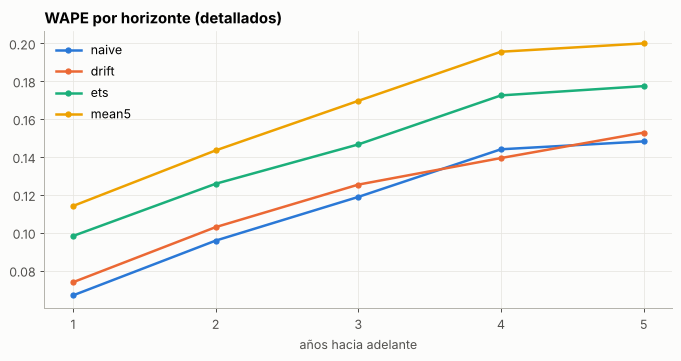

In [5]:
wape_h = det.groupby("horizonte").apply(lambda g: pd.Series({m: (g[m] - g.real).abs().sum() / g.real.abs().sum() for m in ["naive", "drift", "ets", "mean5"]}))
ax = wape_h.plot(marker="o", ms=4, title="WAPE por horizonte (detallados)")
ax.set_xlabel("años hacia adelante"); ax.set_xticks(range(1, 6))
plt.show()

## ¿El ingenuo se ve bueno por los valores repetidos?

In [6]:
dsr = pd.read_csv(RES / "diagnostico_series.csv", dtype={"cod_dane": str})
e = det.assign(ae=(det.naive - det.real).abs()).groupby(["producto", "cod_dane"]).agg(ae=("ae", "sum"), real=("real", "sum"))
e["wape_naive"] = e.ae / e.real.where(e.real > 0)
e = e.join(dsr.set_index(["producto", "cod_dane"])["pct_repetidos"]).dropna()
print("Correlación de Spearman (% repetidos vs WAPE del ingenuo):", round(e[["pct_repetidos", "wape_naive"]].corr("spearman").iloc[0, 1], 3))

Correlación de Spearman (% repetidos vs WAPE del ingenuo): -0.012


**Lectura.** Ningún baseline le gana al ingenuo: con 24 datos anuales y cambios de nivel bruscos, extrapolar tendencias (deriva, ETS) o promediar (promedio 5 años) empeora el error. La correlación entre % de repetidos y error del ingenuo es prácticamente nula, así que los repetidos **no explican** su buen desempeño: lo explica que las series son cortas y casi de nivel constante.